# Confidence Map Contour Explorer

Interactive notebook for exploring segmentation confidence maps with:
- Interactive threshold selection
- Contour visualization with labeled values
- Multi-scale edge detection
- Histogram analysis and automatic threshold suggestions
- Hover-to-see-values interactive heatmaps

## 1. Setup and Imports

In [1]:
# Core libraries
import numpy as np
import cv2
import matplotlib.pyplot as plt
from matplotlib.widgets import Slider
from PIL import Image
import os
from pathlib import Path

# Check for optional dependencies
try:
    import ipywidgets as widgets
    from IPython.display import display
    HAS_IPYWIDGETS = True
    print("✓ ipywidgets available")
except ImportError:
    HAS_IPYWIDGETS = False
    print("⚠ ipywidgets not available. Install with: pip install ipywidgets")

try:
    import plotly.graph_objects as go
    import plotly.express as px
    HAS_PLOTLY = True
    print("✓ plotly available")
except ImportError:
    HAS_PLOTLY = False
    print("⚠ plotly not available. Install with: pip install plotly")

# Set matplotlib style
plt.style.use('default')
%matplotlib inline

print("\nSetup complete!")

✓ ipywidgets available
⚠ plotly not available. Install with: pip install plotly

Setup complete!


## 2. Data Loading

Load a sample image and its corresponding wall confidence map.

In [2]:
# Configuration - Update these paths to your data
BASE_PATH = Path('../rgb-x_output/batch_output')

# List available samples
if BASE_PATH.exists():
    available_samples = [d for d in BASE_PATH.iterdir() if d.is_dir()]
    print(f"Found {len(available_samples)} samples:")
    for i, sample in enumerate(available_samples[:10]):  # Show first 10
        print(f"  {i}: {sample.name}")
    if len(available_samples) > 10:
        print(f"  ... and {len(available_samples) - 10} more")
else:
    print(f"⚠ Path not found: {BASE_PATH}")
    print("Please update BASE_PATH to point to your output directory")

Found 12 samples:
  0: bed_back_bedroom
  1: fluted_walls_living
  2: complex_living
  3: perspective_living
  4: simple_living
  5: simple_living_2
  6: no_walls_living
  7: simple_living_3
  8: obstacle_course_living
  9: room1
  ... and 2 more


In [3]:
# Select a sample to work with (change index as needed)
SAMPLE_INDEX = 0  # Change this to explore different samples

if BASE_PATH.exists() and available_samples:
    sample_dir = available_samples[SAMPLE_INDEX]
    sample_name = sample_dir.name
    
    # Load confidence map
    confidence_path = sample_dir / f"{sample_name}_wall_confidence.npy"
    if confidence_path.exists():
        wall_confidence = np.load(confidence_path)
        print(f"✓ Loaded confidence map: {confidence_path.name}")
        print(f"  Shape: {wall_confidence.shape}")
        print(f"  Range: [{wall_confidence.min():.3f}, {wall_confidence.max():.3f}]")
        print(f"  Mean: {wall_confidence.mean():.3f}")
        print(f"  Std: {wall_confidence.std():.3f}")
    else:
        print(f"⚠ Confidence file not found: {confidence_path}")
    
    # Load original RGB image
    rgb_path = sample_dir / f"{sample_name}.jpg"
    if rgb_path.exists():
        rgb_img = np.array(Image.open(rgb_path))
        print(f"\n✓ Loaded RGB image: {rgb_path.name}")
        print(f"  Shape: {rgb_img.shape}")
    else:
        print(f"\n⚠ RGB file not found: {rgb_path}")
        # Create placeholder
        rgb_img = np.zeros((*wall_confidence.shape, 3), dtype=np.uint8)
        print("  Using blank placeholder image")
else:
    print("⚠ No samples available. Please check BASE_PATH configuration.")

✓ Loaded confidence map: bed_back_bedroom_wall_confidence.npy
  Shape: (700, 1200)
  Range: [0.000, 1.000]
  Mean: 0.283
  Std: 0.423

✓ Loaded RGB image: bed_back_bedroom.jpg
  Shape: (700, 1200, 3)


## 3. Quick Preview

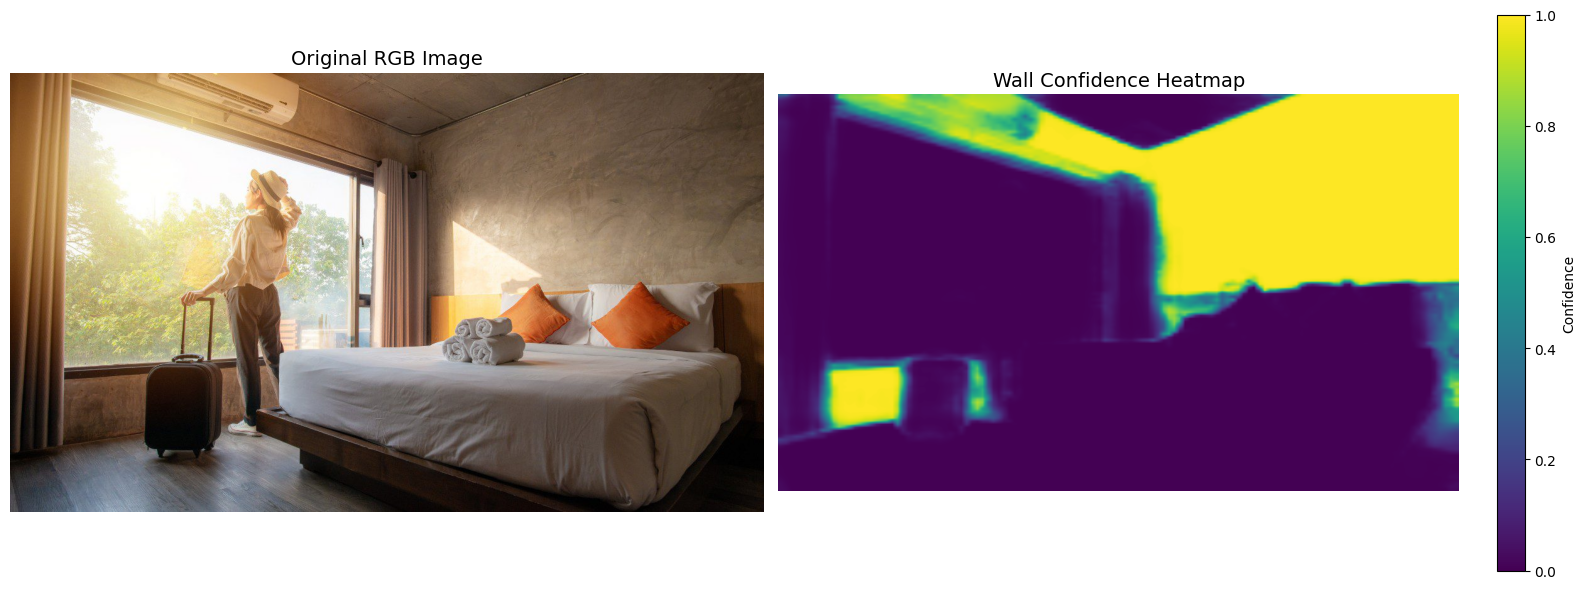

In [4]:
if 'wall_confidence' in globals() and 'rgb_img' in globals():
    fig, axes = plt.subplots(1, 2, figsize=(16, 6))
    
    axes[0].imshow(rgb_img)
    axes[0].set_title('Original RGB Image', fontsize=14)
    axes[0].axis('off')
    
    im = axes[1].imshow(wall_confidence, cmap='viridis', vmin=0, vmax=1)
    axes[1].set_title('Wall Confidence Heatmap', fontsize=14)
    axes[1].axis('off')
    plt.colorbar(im, ax=axes[1], label='Confidence', fraction=0.046)
    
    plt.tight_layout()
    plt.show()
else:
    print("⚠ Data not loaded. Run the previous cells first.")

## 4. Interactive Threshold Selector (ipywidgets)

**RECOMMENDED**: This provides the best interactive experience for finding the right threshold.

Move the slider to see real-time updates of:
- Binary mask at the selected threshold
- Contours extracted from the mask
- Overlay visualization
- Statistics and histogram

In [5]:
def interactive_threshold_explorer(data, original_img):
    """
    Interactive threshold selector with comprehensive visualization.
    
    Args:
        data: numpy array of confidence values (H x W)
        original_img: RGB image as numpy array (H x W x 3)
    """
    if not HAS_IPYWIDGETS:
        print("⚠ ipywidgets not available. Please install: pip install ipywidgets")
        print("Falling back to matplotlib slider (see next section)")
        return
    
    # Create slider
    threshold_slider = widgets.FloatSlider(
        value=0.5,
        min=0.0,
        max=1.0,
        step=0.01,
        description='Threshold:',
        continuous_update=True,
        readout_format='.3f',
        style={'description_width': '100px'},
        layout=widgets.Layout(width='80%')
    )
    
    # Create output widget
    output = widgets.Output()
    
    def update_visualization(change):
        threshold = change['new']
        
        with output:
            output.clear_output(wait=True)
            
            # Create visualization
            fig, axes = plt.subplots(2, 3, figsize=(20, 12))
            
            # 1. Original image
            axes[0, 0].imshow(original_img)
            axes[0, 0].set_title('Original Image', fontsize=14, fontweight='bold')
            axes[0, 0].axis('off')
            
            # 2. Confidence heatmap
            im1 = axes[0, 1].imshow(data, cmap='viridis', vmin=0, vmax=1)
            plt.colorbar(im1, ax=axes[0, 1], label='Confidence')
            axes[0, 1].set_title('Confidence Heatmap', fontsize=14, fontweight='bold')
            axes[0, 1].axis('off')
            
            # 3. Binary mask
            binary = data > threshold
            axes[0, 2].imshow(binary, cmap='gray')
            pixels_above = np.sum(binary)
            percentage = (pixels_above / binary.size) * 100
            axes[0, 2].set_title(
                f'Binary Mask (t={threshold:.3f})\n{pixels_above:,} pixels ({percentage:.1f}%)',
                fontsize=14,
                fontweight='bold'
            )
            axes[0, 2].axis('off')
            
            # 4. Contours on original
            binary_uint8 = (binary * 255).astype(np.uint8)
            contours, _ = cv2.findContours(
                binary_uint8,
                cv2.RETR_EXTERNAL,
                cv2.CHAIN_APPROX_SIMPLE
            )
            
            contour_img = original_img.copy()
            cv2.drawContours(contour_img, contours, -1, (255, 0, 0), 2)
            axes[1, 0].imshow(contour_img)
            axes[1, 0].set_title(
                f'Contours on Original\n{len(contours)} contour(s) found',
                fontsize=14,
                fontweight='bold'
            )
            axes[1, 0].axis('off')
            
            # 5. Overlay
            overlay = original_img.copy().astype(float)
            overlay[binary] = overlay[binary] * 0.6 + np.array([255, 0, 0]) * 0.4
            axes[1, 1].imshow(overlay.astype(np.uint8))
            axes[1, 1].set_title('Overlay (Red = Above Threshold)', fontsize=14, fontweight='bold')
            axes[1, 1].axis('off')
            
            # 6. Histogram with threshold line
            axes[1, 2].hist(data.flatten(), bins=50, alpha=0.7,
                           color='steelblue', edgecolor='black')
            axes[1, 2].axvline(x=threshold, color='red', linestyle='--',
                              linewidth=2.5, label=f'Threshold = {threshold:.3f}')
            axes[1, 2].set_xlabel('Confidence Value', fontsize=12)
            axes[1, 2].set_ylabel('Frequency', fontsize=12)
            axes[1, 2].set_title('Value Distribution', fontsize=14, fontweight='bold')
            axes[1, 2].legend(fontsize=11)
            axes[1, 2].grid(True, alpha=0.3)
            
            plt.tight_layout()
            plt.show()
    
    # Connect slider to update function
    threshold_slider.observe(update_visualization, names='value')
    
    # Display widgets
    display(widgets.VBox([
        widgets.HTML(value="<h3>Interactive Threshold Explorer</h3>"),
        threshold_slider,
        output
    ]))
    
    # Trigger initial visualization
    update_visualization({'new': threshold_slider.value})
    
    return threshold_slider

# Run the interactive explorer
if 'wall_confidence' in globals() and 'rgb_img' in globals():
    slider = interactive_threshold_explorer(wall_confidence, rgb_img)
    # Access the final threshold value with: slider.value
else:
    print("⚠ Data not loaded. Run the data loading cells first.")

## 5. Labeled Contour Plots

Visualize specific contour levels with labeled values.

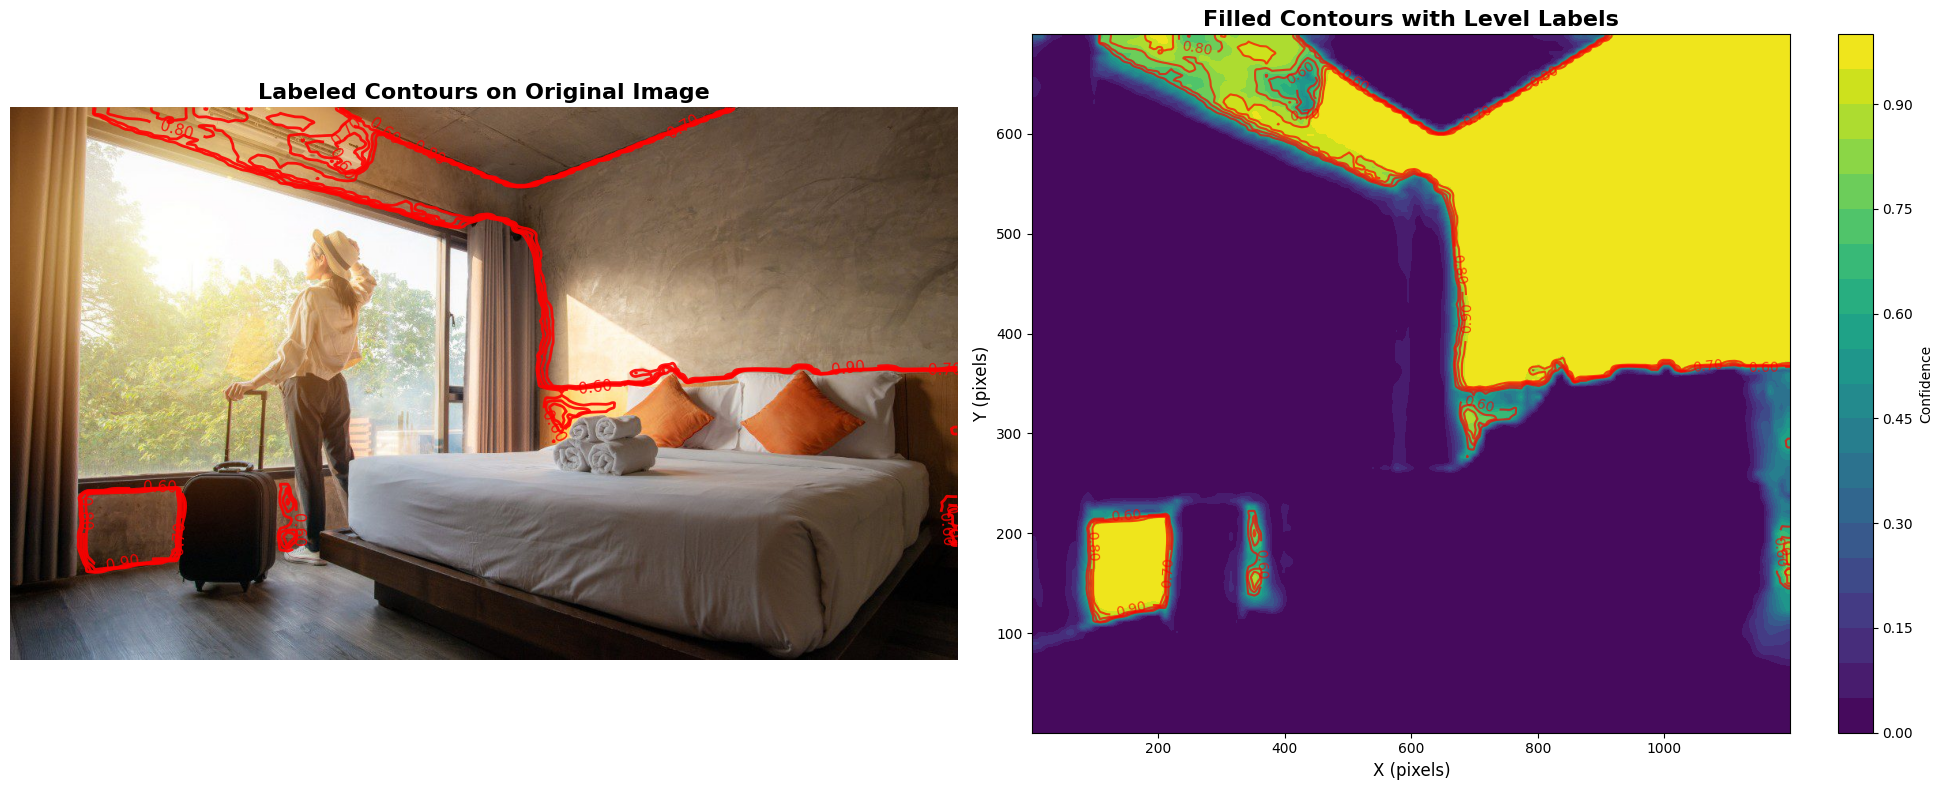

In [23]:
def plot_labeled_contours(data, original_img, levels=None):
    """
    Create contour plots with labeled contour levels.
    
    Args:
        data: numpy array of confidence values
        original_img: RGB image
        levels: list of contour levels, or int for number of levels
    """
    if levels is None:
        levels = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]
    
    fig, axes = plt.subplots(1, 2, figsize=(20, 8))
    
    # Left: Contours on original image
    axes[0].imshow(original_img)
    contours = axes[0].contour(data, levels=levels, colors='red',
                               linewidths=2, alpha=0.9)
    axes[0].clabel(contours, inline=True, fontsize=11, fmt='%.2f')
    axes[0].set_title('Labeled Contours on Original Image', fontsize=16, fontweight='bold')
    axes[0].axis('off')
    
    # Right: Filled contours
    contourf = axes[1].contourf(data, levels=20, cmap='viridis', origin='upper')
    contours2 = axes[1].contour(data, levels=levels, colors='red',
                                linewidths=1.5, alpha=0.7, origin='upper')
    axes[1].clabel(contours2, inline=True, fontsize=10, fmt='%.2f',
                  colors='red')
    plt.colorbar(contourf, ax=axes[1], label='Confidence')
    axes[1].set_title('Filled Contours with Level Labels', fontsize=16, fontweight='bold')
    axes[1].set_xlabel('X (pixels)', fontsize=12)
    axes[1].set_ylabel('Y (pixels)', fontsize=12)
    
    plt.tight_layout()
    plt.show()

    return contours, contours2

# Run the contour plot
if 'wall_confidence' in globals() and 'rgb_img' in globals():
    # You can customize the levels here
    custom_levels = [0.6, 0.7, 0.8, 0.9]
    img_cont, hmap_cont = plot_labeled_contours(wall_confidence, rgb_img, levels=custom_levels)
else:
    print("⚠ Data not loaded. Run the data loading cells first.")

✓ Images saved to: /Users/ishan-aiworkspace/Documents/apps/rgb-x/rgb-x_output/batch_output/bed_back_bedroom/contour_explorer


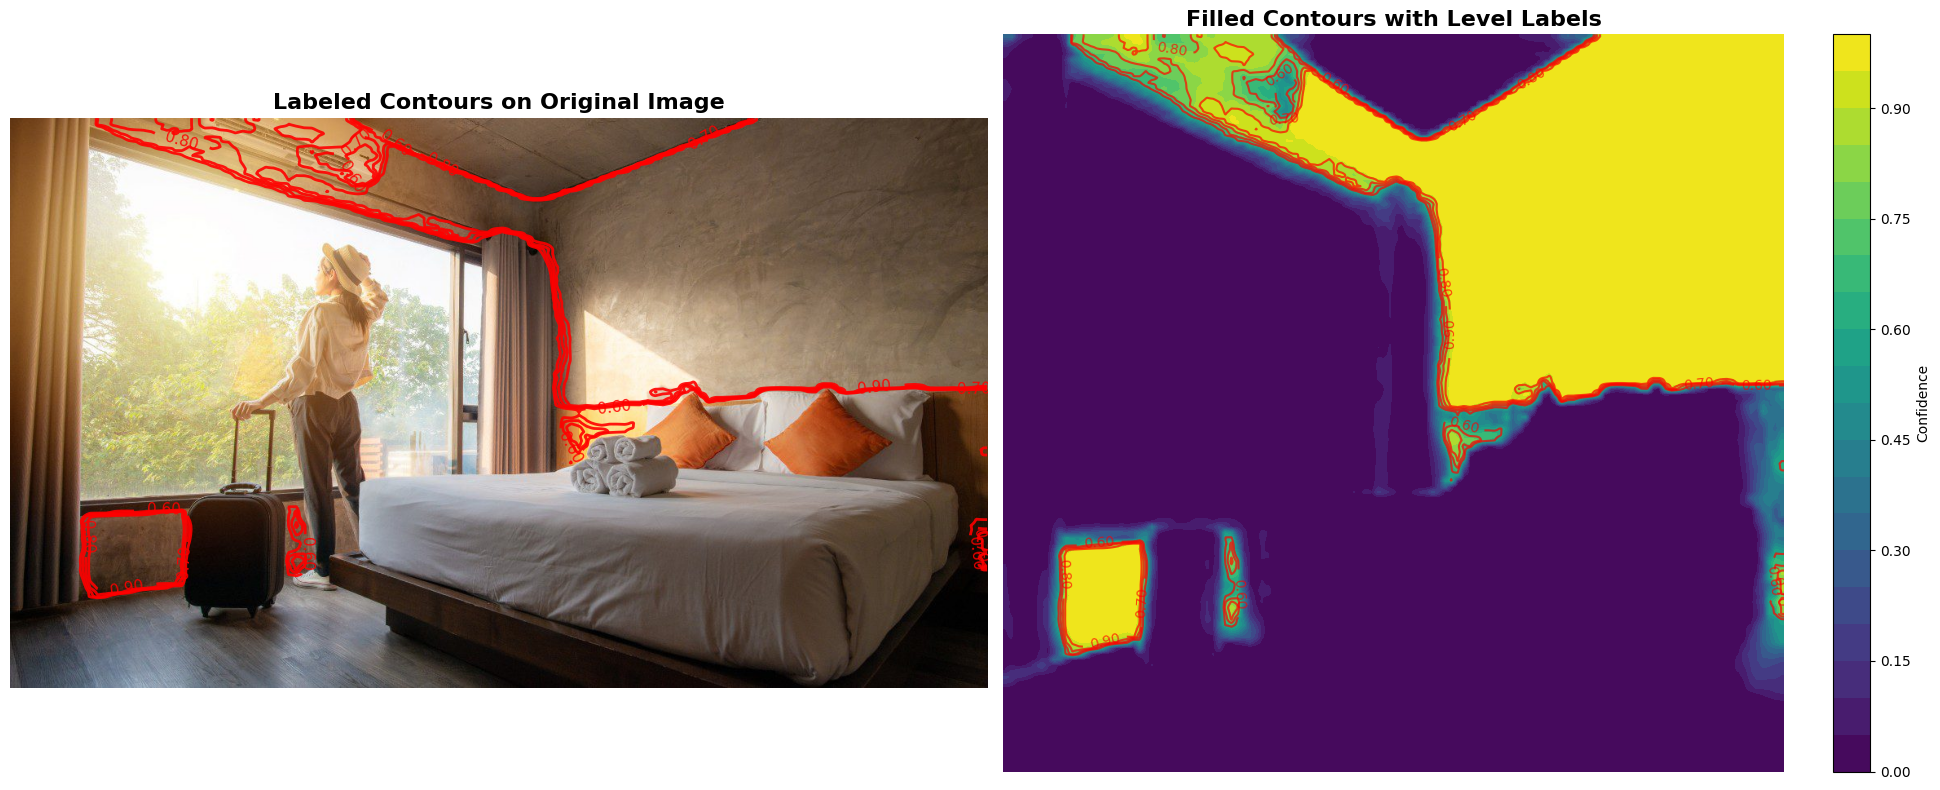

In [29]:
def plot_labeled_contours(data, original_img, levels=None, save_dir=None):
    """
    Create contour plots with labeled contour levels.
    
    Args:
        data: numpy array of confidence values
        original_img: RGB image
        levels: list of contour levels, or int for number of levels
        save_dir: directory to save the output images (optional)
    """
    if levels is None:
        levels = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]
    
    fig, axes = plt.subplots(1, 2, figsize=(20, 8))
    
    # Left: Contours on original image
    axes[0].imshow(original_img)
    contours = axes[0].contour(data, levels=levels, colors='red',
                               linewidths=2, alpha=0.9)
    axes[0].clabel(contours, inline=True, fontsize=11, fmt='%.2f')
    axes[0].set_title('Labeled Contours on Original Image', fontsize=16, fontweight='bold')
    axes[0].axis('off')
    
    # Right: Filled contours
    contourf = axes[1].contourf(data, levels=20, cmap='viridis', origin='upper')
    contours2 = axes[1].contour(data, levels=levels, colors='red',
                                linewidths=1.5, alpha=0.7, origin='upper')
    axes[1].clabel(contours2, inline=True, fontsize=10, fmt='%.2f',
                  colors='red')
    plt.colorbar(contourf, ax=axes[1], label='Confidence')
    axes[1].set_title('Filled Contours with Level Labels', fontsize=16, fontweight='bold')
    # axes[1].set_xlabel('X (pixels)', fontsize=12)
    # axes[1].set_ylabel('Y (pixels)', fontsize=12)
    # axes[1].set_aspect(data.shape[1] / data.shape[0])
    axes[1].axis('off')
    
    plt.tight_layout()
    
    # Save images if directory is provided
    if save_dir:
        import os
        os.makedirs(save_dir, exist_ok=True)
        
        # Save the complete figure
        fig.savefig(os.path.join(save_dir, 'contours_combined.png'), 
                    dpi=150, bbox_inches='tight')
        
        # Save individual panels
        # Left panel
        extent = axes[0].get_window_extent().transformed(fig.dpi_scale_trans.inverted())
        fig.savefig(os.path.join(save_dir, 'contours_on_image.png'), 
                    dpi=150, bbox_inches=extent.expanded(1.1, 1.1))
        
        # Right panel
        extent = axes[1].get_window_extent().transformed(fig.dpi_scale_trans.inverted())
        fig.savefig(os.path.join(save_dir, 'filled_contours.png'), 
                    dpi=150, bbox_inches=extent.expanded(1.1, 1.1))
        
        print(f"✓ Images saved to: {save_dir}")
    
    plt.show()
    
    return contours, contours2

# Run the contour plot
if 'wall_confidence' in globals() and 'rgb_img' in globals():
    # You can customize the levels here
    custom_levels = [0.6, 0.7, 0.8, 0.9]
    save_directory = "/Users/ishan-aiworkspace/Documents/apps/rgb-x/rgb-x_output/batch_output/bed_back_bedroom/contour_explorer"
    img_cont, hmap_cont = plot_labeled_contours(wall_confidence, rgb_img, 
                                                 levels=custom_levels, 
                                                 save_dir=save_directory)
else:
    print("⚠ Data not loaded. Run the data loading cells first.")


## 6. Multi-Scale Edge Detection

Detect edges at different scales to find sharp transitions in confidence values.

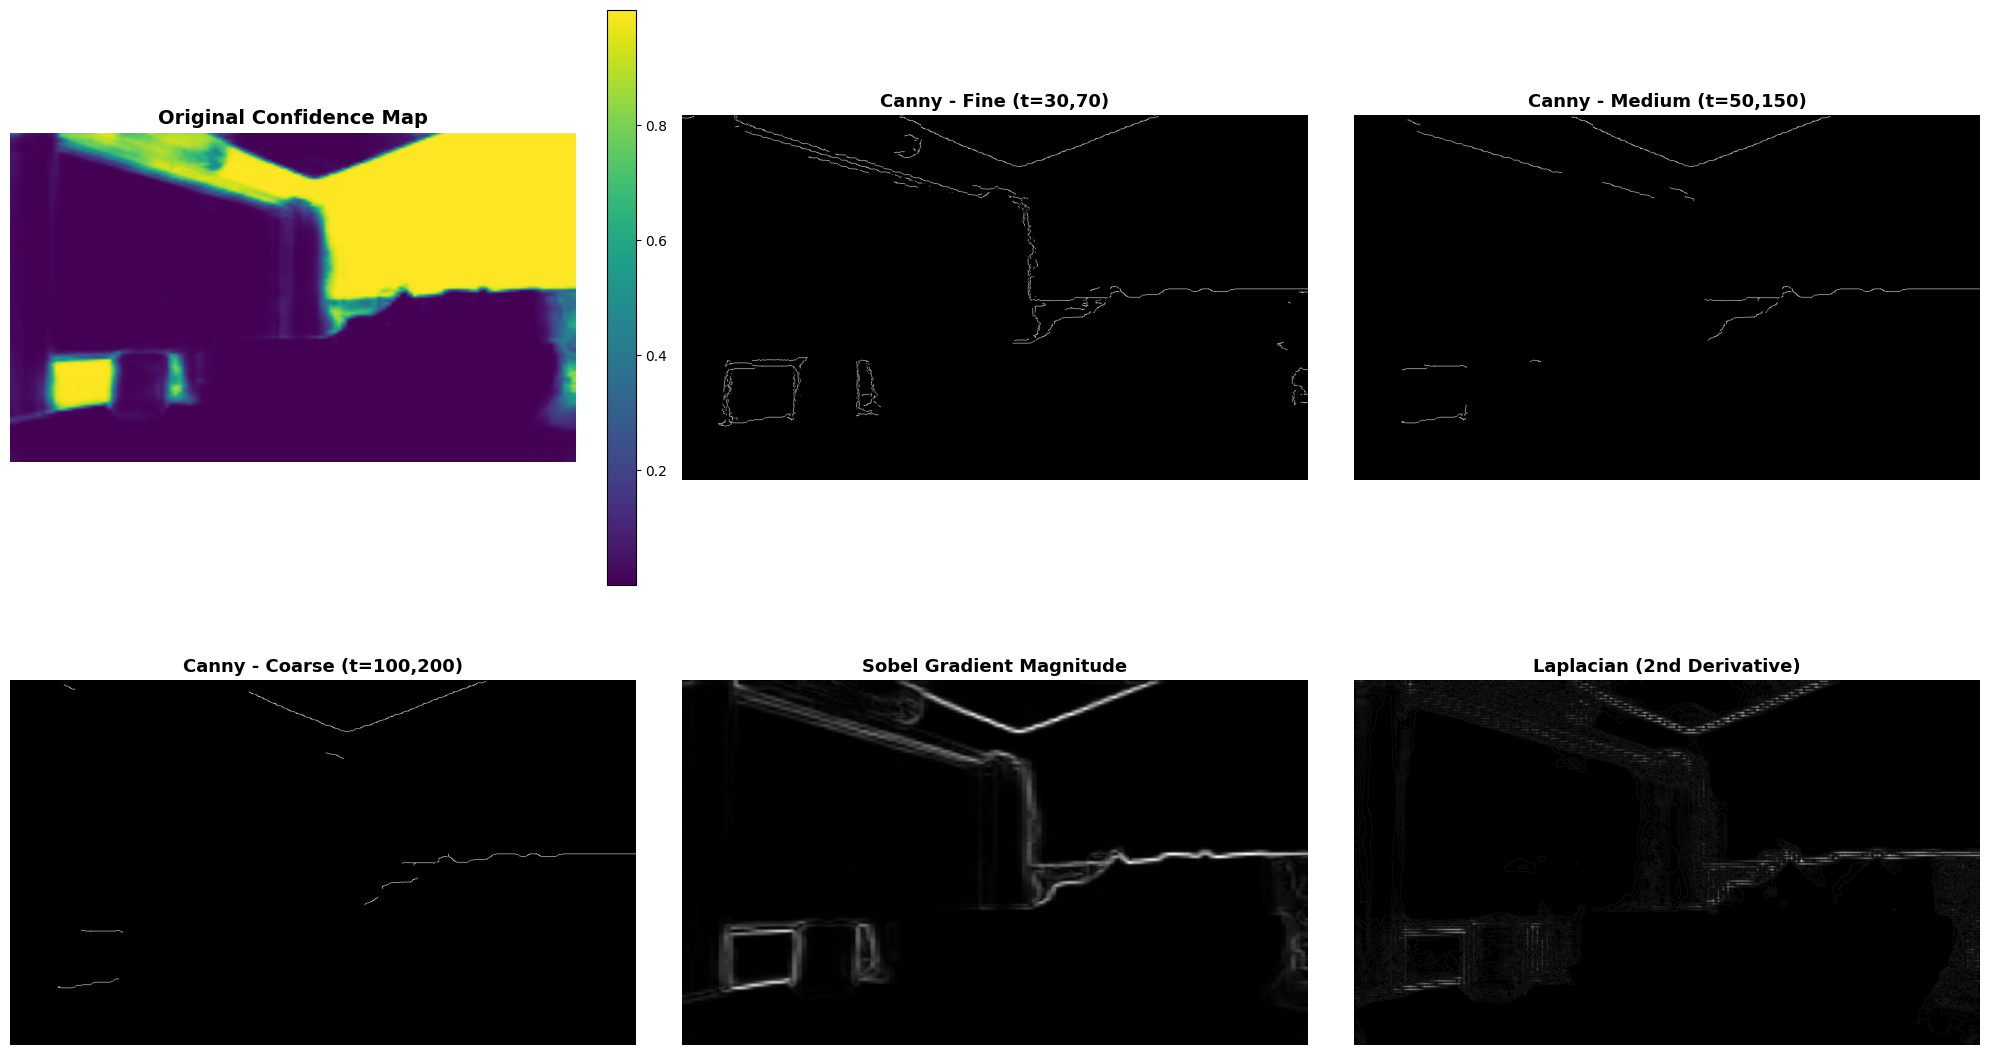

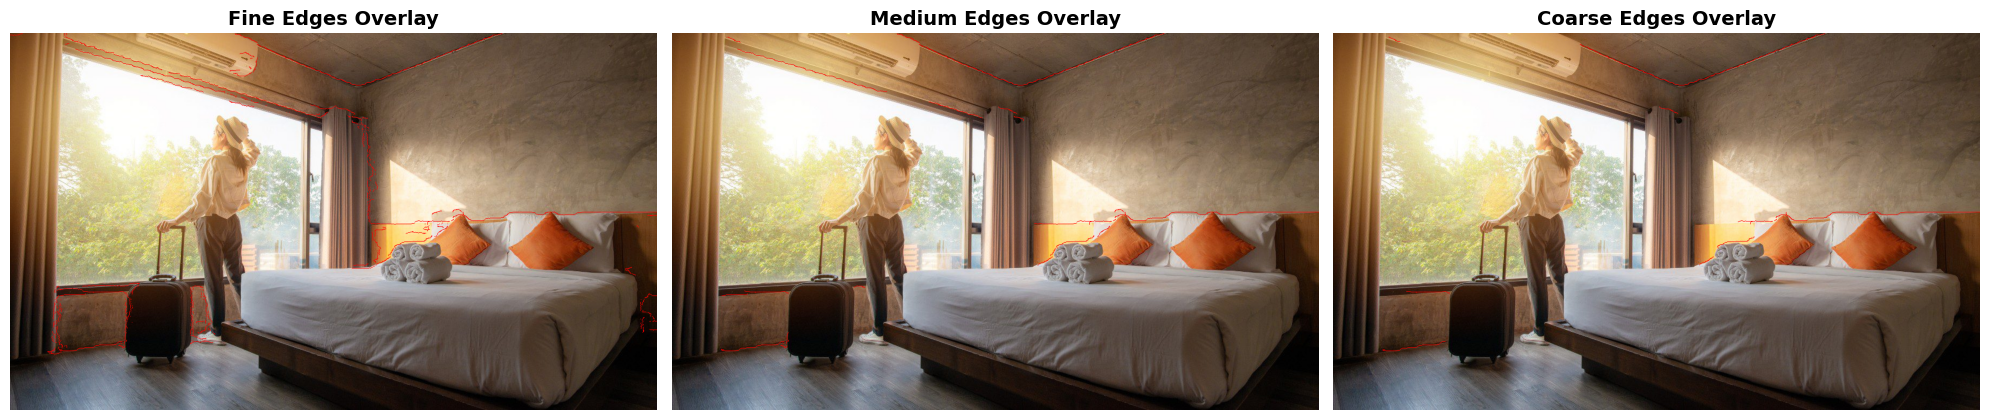

In [7]:
def multi_scale_edge_detection(data, original_img=None):
    """
    Apply multiple edge detection methods at different scales.
    
    Args:
        data: numpy array of confidence values
        original_img: optional RGB image to overlay edges on
    """
    # Convert to uint8 for OpenCV
    data_uint8 = (data * 255).astype(np.uint8)
    
    # Apply Gaussian blur first
    blurred = cv2.GaussianBlur(data_uint8, (5, 5), 0)
    
    # Canny with different thresholds
    edges_fine = cv2.Canny(blurred, 30, 70)      # Fine details
    edges_medium = cv2.Canny(blurred, 50, 150)   # Medium (standard)
    edges_coarse = cv2.Canny(blurred, 100, 200)  # Coarse (strong edges only)
    
    # Sobel gradients
    sobelx = cv2.Sobel(blurred, cv2.CV_64F, 1, 0, ksize=3)
    sobely = cv2.Sobel(blurred, cv2.CV_64F, 0, 1, ksize=3)
    sobel_mag = np.sqrt(sobelx**2 + sobely**2)
    sobel_mag = cv2.normalize(sobel_mag, None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)
    
    # Laplacian (second derivative)
    laplacian = cv2.Laplacian(blurred, cv2.CV_64F)
    laplacian = cv2.normalize(np.abs(laplacian), None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)
    
    # Visualization
    fig, axes = plt.subplots(2, 3, figsize=(20, 12))
    axes = axes.flatten()
    
    # Original data
    im0 = axes[0].imshow(data, cmap='viridis')
    axes[0].set_title('Original Confidence Map', fontsize=14, fontweight='bold')
    axes[0].axis('off')
    plt.colorbar(im0, ax=axes[0], fraction=0.046)
    
    # Edge detection results
    edge_results = [
        ('Canny - Fine (t=30,70)', edges_fine),
        ('Canny - Medium (t=50,150)', edges_medium),
        ('Canny - Coarse (t=100,200)', edges_coarse),
        ('Sobel Gradient Magnitude', sobel_mag),
        ('Laplacian (2nd Derivative)', laplacian)
    ]
    
    for idx, (title, edge_img) in enumerate(edge_results, start=1):
        axes[idx].imshow(edge_img, cmap='gray')
        axes[idx].set_title(title, fontsize=13, fontweight='bold')
        axes[idx].axis('off')
    
    plt.tight_layout()
    plt.show()
    
    # Optional: Overlay edges on original image
    if original_img is not None:
        fig, axes = plt.subplots(1, 3, figsize=(20, 6))
        
        for idx, (title, edges) in enumerate([
            ('Fine Edges', edges_fine),
            ('Medium Edges', edges_medium),
            ('Coarse Edges', edges_coarse)
        ]):
            overlay = original_img.copy()
            overlay[edges > 0] = [255, 0, 0]  # Red edges
            axes[idx].imshow(overlay)
            axes[idx].set_title(f'{title} Overlay', fontsize=14, fontweight='bold')
            axes[idx].axis('off')
        
        plt.tight_layout()
        plt.show()
    
    return {
        'canny_fine': edges_fine,
        'canny_medium': edges_medium,
        'canny_coarse': edges_coarse,
        'sobel': sobel_mag,
        'laplacian': laplacian
    }

# Run edge detection
if 'wall_confidence' in globals():
    edges_dict = multi_scale_edge_detection(wall_confidence, rgb_img if 'rgb_img' in globals() else None)
else:
    print("⚠ Data not loaded. Run the data loading cells first.")

## 7. Histogram Analysis & Automatic Threshold Suggestions

Analyze the value distribution and get automatic threshold suggestions.

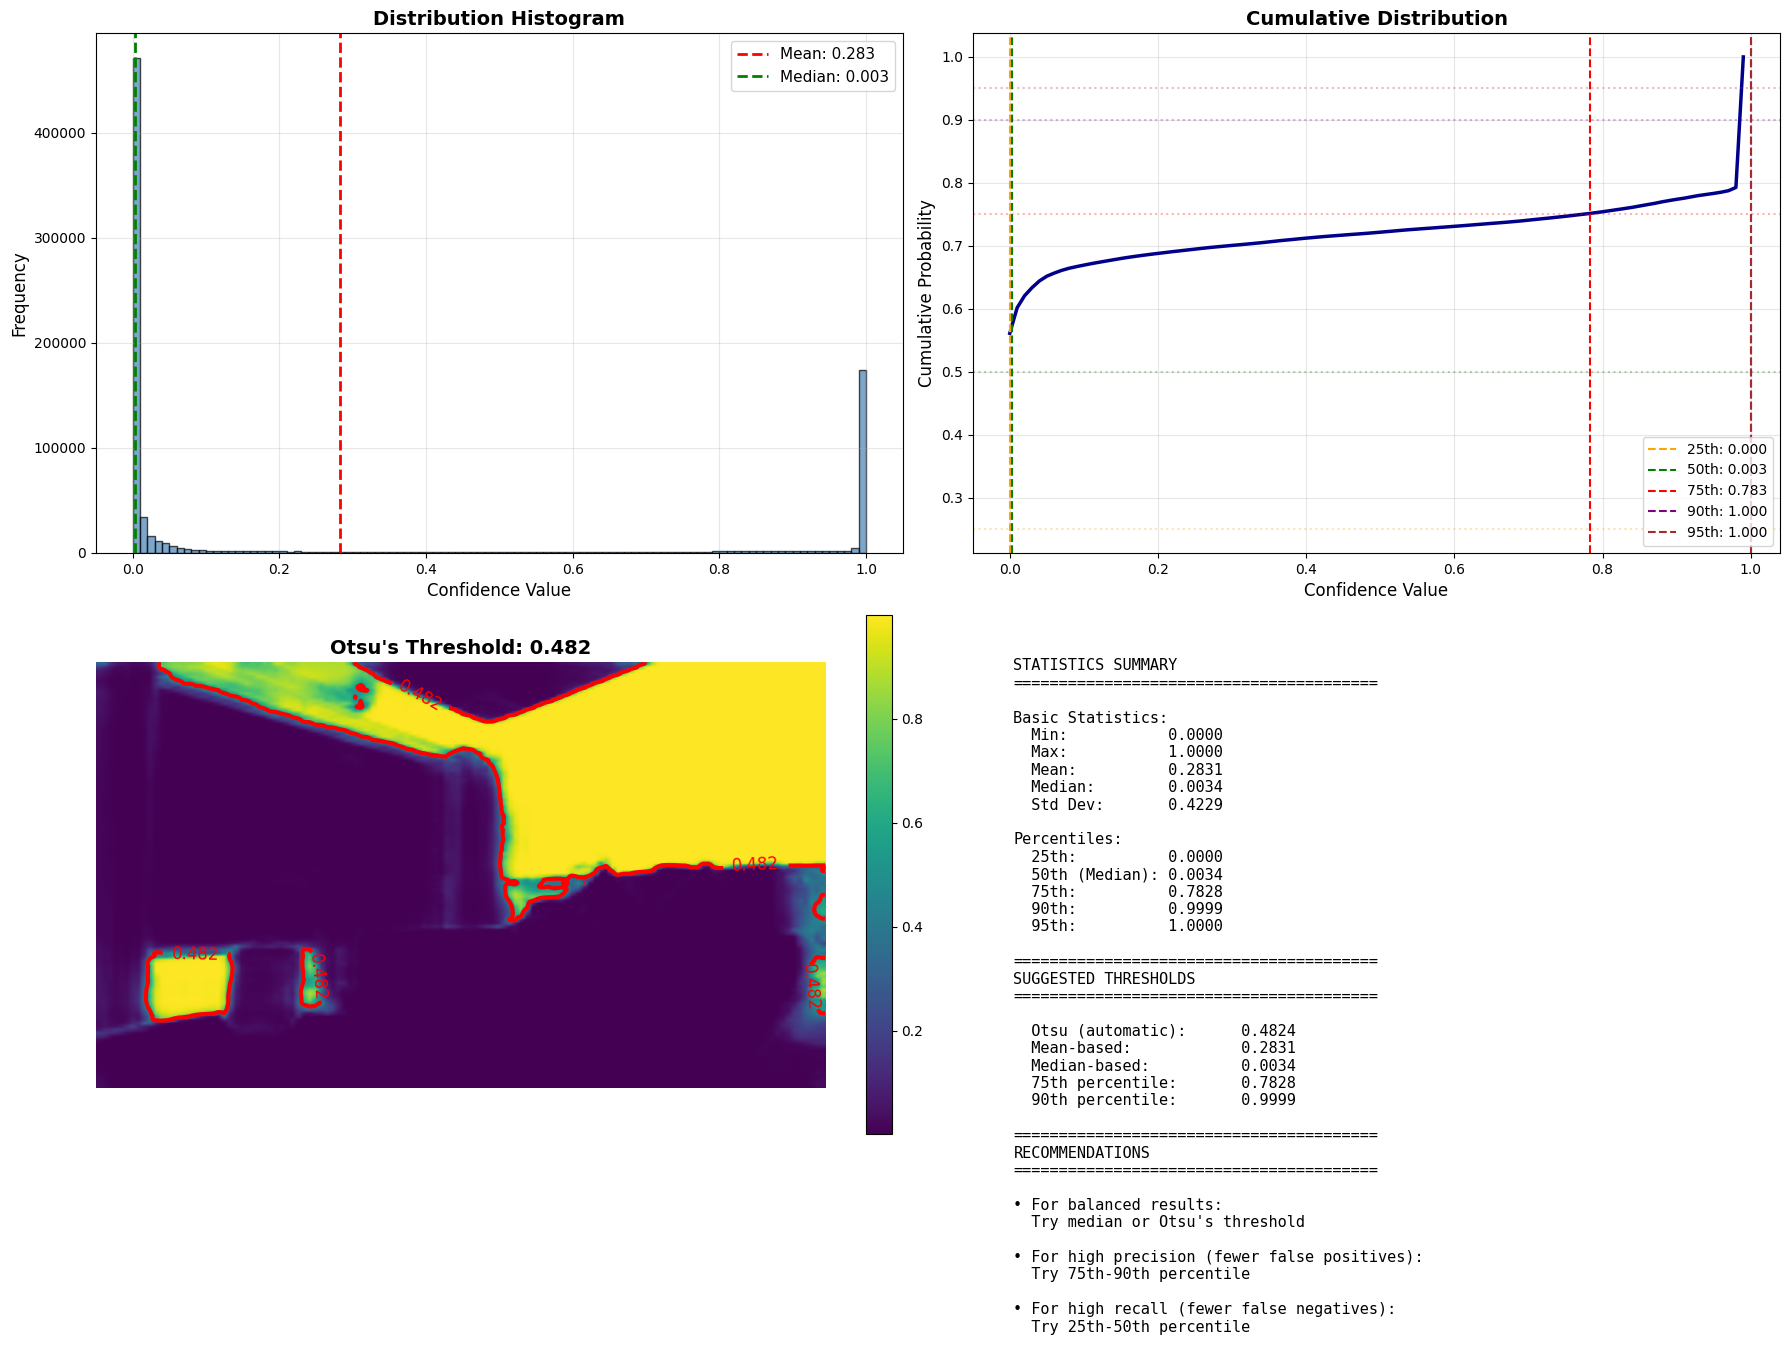


Suggested thresholds stored in 'suggested_thresholds' dictionary
Access with: suggested_thresholds['otsu'], suggested_thresholds['mean'], etc.


In [8]:
def histogram_threshold_analysis(data):
    """
    Comprehensive histogram analysis with automatic threshold suggestions.
    
    Args:
        data: numpy array of confidence values
        
    Returns:
        dict: Dictionary of suggested thresholds
    """
    fig, axes = plt.subplots(2, 2, figsize=(18, 14))
    
    # 1. Histogram
    axes[0, 0].hist(data.flatten(), bins=100, alpha=0.7,
                    color='steelblue', edgecolor='black')
    axes[0, 0].axvline(x=data.mean(), color='red', linestyle='--',
                      linewidth=2, label=f'Mean: {data.mean():.3f}')
    axes[0, 0].axvline(x=np.median(data), color='green', linestyle='--',
                      linewidth=2, label=f'Median: {np.median(data):.3f}')
    axes[0, 0].set_xlabel('Confidence Value', fontsize=12)
    axes[0, 0].set_ylabel('Frequency', fontsize=12)
    axes[0, 0].set_title('Distribution Histogram', fontsize=14, fontweight='bold')
    axes[0, 0].legend(fontsize=11)
    axes[0, 0].grid(True, alpha=0.3)
    
    # 2. Cumulative distribution with percentiles
    hist, bins = np.histogram(data.flatten(), bins=100)
    cumsum = np.cumsum(hist) / hist.sum()
    axes[0, 1].plot(bins[:-1], cumsum, linewidth=2.5, color='darkblue')
    
    # Mark percentiles
    percentiles = [25, 50, 75, 90, 95]
    colors = ['orange', 'green', 'red', 'purple', 'brown']
    for p, color in zip(percentiles, colors):
        threshold = np.percentile(data, p)
        axes[0, 1].axvline(x=threshold, linestyle='--', color=color,
                          linewidth=1.5, label=f'{p}th: {threshold:.3f}')
        axes[0, 1].axhline(y=p/100, linestyle=':', color=color, alpha=0.3)
    
    axes[0, 1].set_xlabel('Confidence Value', fontsize=12)
    axes[0, 1].set_ylabel('Cumulative Probability', fontsize=12)
    axes[0, 1].set_title('Cumulative Distribution', fontsize=14, fontweight='bold')
    axes[0, 1].legend(fontsize=10, loc='lower right')
    axes[0, 1].grid(True, alpha=0.3)
    
    # 3. Spatial distribution with Otsu threshold
    data_uint8 = (data * 255).astype(np.uint8)
    otsu_thresh, _ = cv2.threshold(data_uint8, 0, 255,
                                   cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    otsu_normalized = otsu_thresh / 255.0
    
    im2 = axes[1, 0].imshow(data, cmap='viridis')
    contour = axes[1, 0].contour(data, levels=[otsu_normalized],
                                 colors='red', linewidths=3)
    axes[1, 0].clabel(contour, inline=True, fontsize=12, fmt='%.3f')
    axes[1, 0].set_title(f"Otsu's Threshold: {otsu_normalized:.3f}",
                        fontsize=14, fontweight='bold')
    axes[1, 0].axis('off')
    plt.colorbar(im2, ax=axes[1, 0], fraction=0.046)
    
    # 4. Statistics summary
    axes[1, 1].axis('off')
    
    # Calculate suggested thresholds
    suggestions = {
        'otsu': otsu_normalized,
        'mean': data.mean(),
        'median': np.median(data),
        'p75': np.percentile(data, 75),
        'p90': np.percentile(data, 90)
    }
    
    stats_text = f"""
STATISTICS SUMMARY
{'='*40}

Basic Statistics:
  Min:           {data.min():.4f}
  Max:           {data.max():.4f}
  Mean:          {data.mean():.4f}
  Median:        {np.median(data):.4f}
  Std Dev:       {data.std():.4f}

Percentiles:
  25th:          {np.percentile(data, 25):.4f}
  50th (Median): {np.percentile(data, 50):.4f}
  75th:          {np.percentile(data, 75):.4f}
  90th:          {np.percentile(data, 90):.4f}
  95th:          {np.percentile(data, 95):.4f}

{'='*40}
SUGGESTED THRESHOLDS
{'='*40}

  Otsu (automatic):      {otsu_normalized:.4f}
  Mean-based:            {data.mean():.4f}
  Median-based:          {np.median(data):.4f}
  75th percentile:       {np.percentile(data, 75):.4f}
  90th percentile:       {np.percentile(data, 90):.4f}

{'='*40}
RECOMMENDATIONS
{'='*40}

• For balanced results:
  Try median or Otsu's threshold

• For high precision (fewer false positives):
  Try 75th-90th percentile

• For high recall (fewer false negatives):
  Try 25th-50th percentile
    """
    
    axes[1, 1].text(0.05, 0.95, stats_text, fontsize=11,
                   family='monospace', verticalalignment='top',
                   transform=axes[1, 1].transAxes)
    
    plt.tight_layout()
    plt.show()
    
    return suggestions

# Run histogram analysis
if 'wall_confidence' in globals():
    suggested_thresholds = histogram_threshold_analysis(wall_confidence)
    print("\nSuggested thresholds stored in 'suggested_thresholds' dictionary")
    print("Access with: suggested_thresholds['otsu'], suggested_thresholds['mean'], etc.")
else:
    print("⚠ Data not loaded. Run the data loading cells first.")

## 8. Plotly Interactive Heatmap (Hover to See Values)

**Best for seeing exact values**: Hover over any pixel to see its exact confidence value.

In [9]:
def plotly_interactive_heatmap(data, title="Wall Confidence - Hover for Values"):
    """
    Create an interactive heatmap using Plotly.
    Hover over any pixel to see its exact value.
    
    Args:
        data: numpy array of confidence values
        title: plot title
    """
    if not HAS_PLOTLY:
        print("⚠ plotly not available. Please install: pip install plotly")
        return
    
    # Create heatmap
    fig = go.Figure(data=go.Heatmap(
        z=data,
        colorscale='Viridis',
        hovertemplate='<b>Position</b><br>' +
                      'X: %{x}<br>' +
                      'Y: %{y}<br>' +
                      '<b>Confidence: %{z:.4f}</b><br>' +
                      '<extra></extra>',
        colorbar=dict(
            title="Confidence",
            titleside="right",
            tickmode="linear",
            tick0=0,
            dtick=0.1
        ),
        zmin=0,
        zmax=1
    ))
    
    fig.update_layout(
        title=dict(
            text=title,
            font=dict(size=18)
        ),
        xaxis_title="X (pixels)",
        yaxis_title="Y (pixels)",
        height=700,
        hovermode='closest'
    )
    
    # Reverse y-axis to match image coordinates
    fig.update_yaxes(autorange='reversed')
    
    fig.show()

# Run interactive heatmap
if 'wall_confidence' in globals():
    plotly_interactive_heatmap(wall_confidence)
else:
    print("⚠ Data not loaded. Run the data loading cells first.")

⚠ plotly not available. Please install: pip install plotly


## 9. Compare Multiple Thresholds Side-by-Side

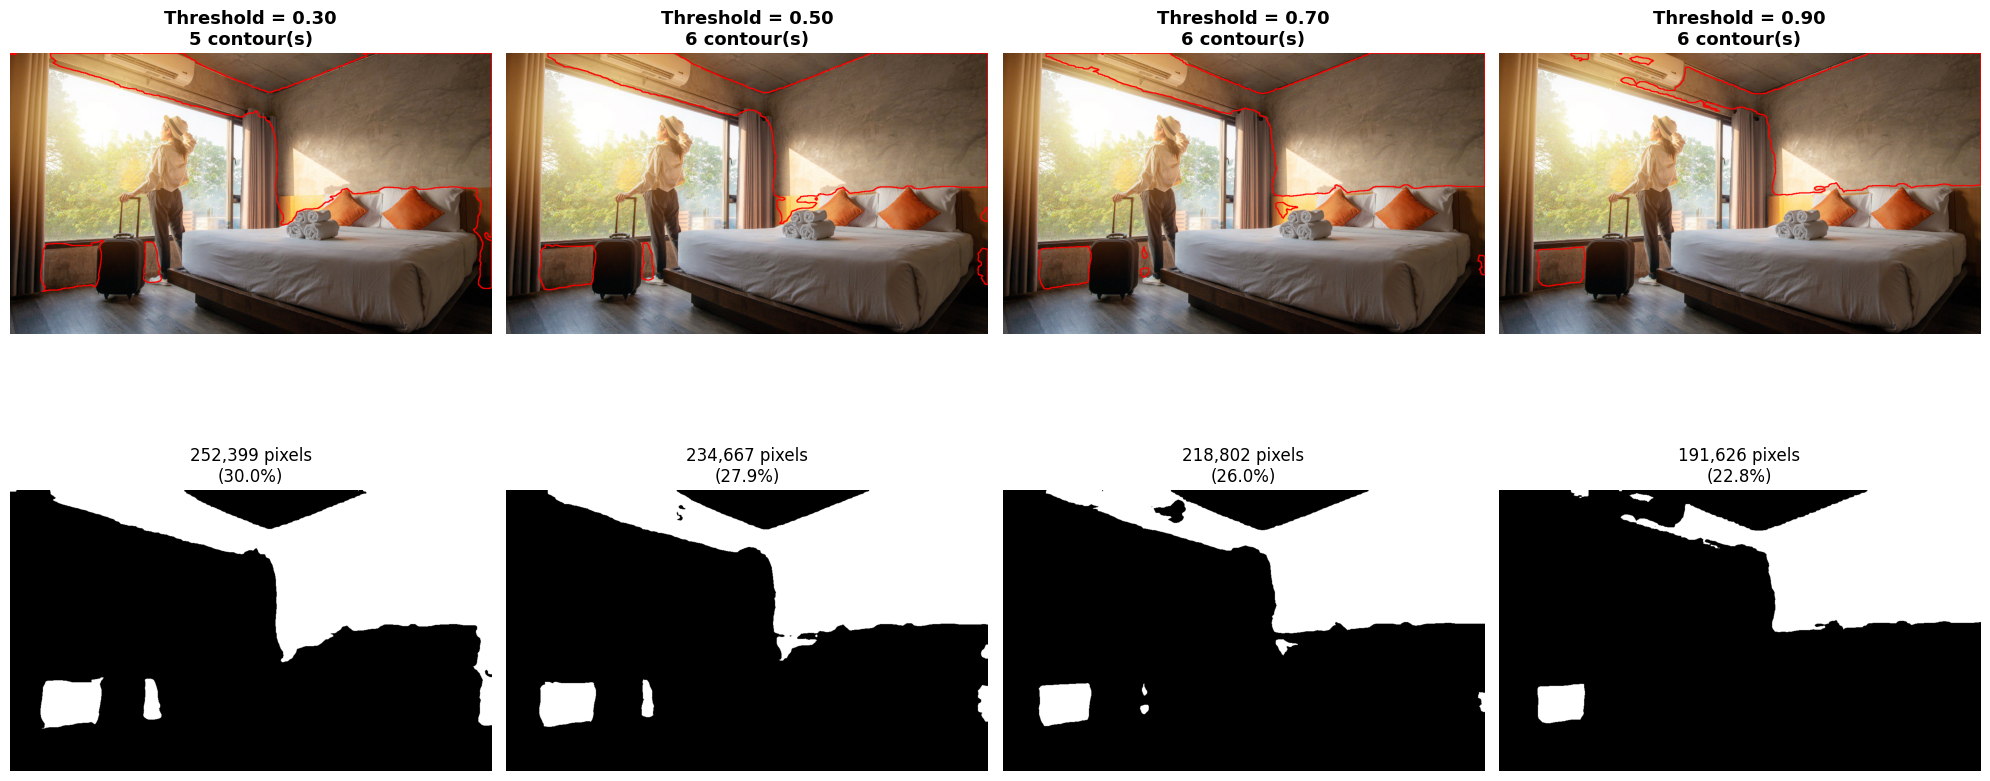

In [10]:
def compare_thresholds(data, original_img, thresholds):
    """
    Compare results of different threshold values side-by-side.
    
    Args:
        data: numpy array of confidence values
        original_img: RGB image
        thresholds: list of threshold values to compare
    """
    n_thresholds = len(thresholds)
    fig, axes = plt.subplots(2, n_thresholds, figsize=(5*n_thresholds, 10))
    
    if n_thresholds == 1:
        axes = axes.reshape(-1, 1)
    
    for idx, threshold in enumerate(thresholds):
        # Binary mask
        binary = data > threshold
        binary_uint8 = (binary * 255).astype(np.uint8)
        
        # Find contours
        contours, _ = cv2.findContours(
            binary_uint8,
            cv2.RETR_EXTERNAL,
            cv2.CHAIN_APPROX_SIMPLE
        )
        
        # Contour overlay
        contour_img = original_img.copy()
        cv2.drawContours(contour_img, contours, -1, (255, 0, 0), 2)
        
        # Statistics
        pixels_above = np.sum(binary)
        percentage = (pixels_above / binary.size) * 100
        
        # Display contours
        axes[0, idx].imshow(contour_img)
        axes[0, idx].set_title(
            f'Threshold = {threshold:.2f}\n{len(contours)} contour(s)',
            fontsize=13,
            fontweight='bold'
        )
        axes[0, idx].axis('off')
        
        # Display binary mask
        axes[1, idx].imshow(binary, cmap='gray')
        axes[1, idx].set_title(
            f'{pixels_above:,} pixels\n({percentage:.1f}%)',
            fontsize=12
        )
        axes[1, idx].axis('off')
    
    plt.tight_layout()
    plt.show()

# Compare some common thresholds
if 'wall_confidence' in globals() and 'rgb_img' in globals():
    # You can customize these thresholds
    thresholds_to_compare = [0.3, 0.5, 0.7, 0.9]
    compare_thresholds(wall_confidence, rgb_img, thresholds_to_compare)
else:
    print("⚠ Data not loaded. Run the data loading cells first.")

## 10. Export Selected Threshold

Once you've found a good threshold, use this cell to save the results.

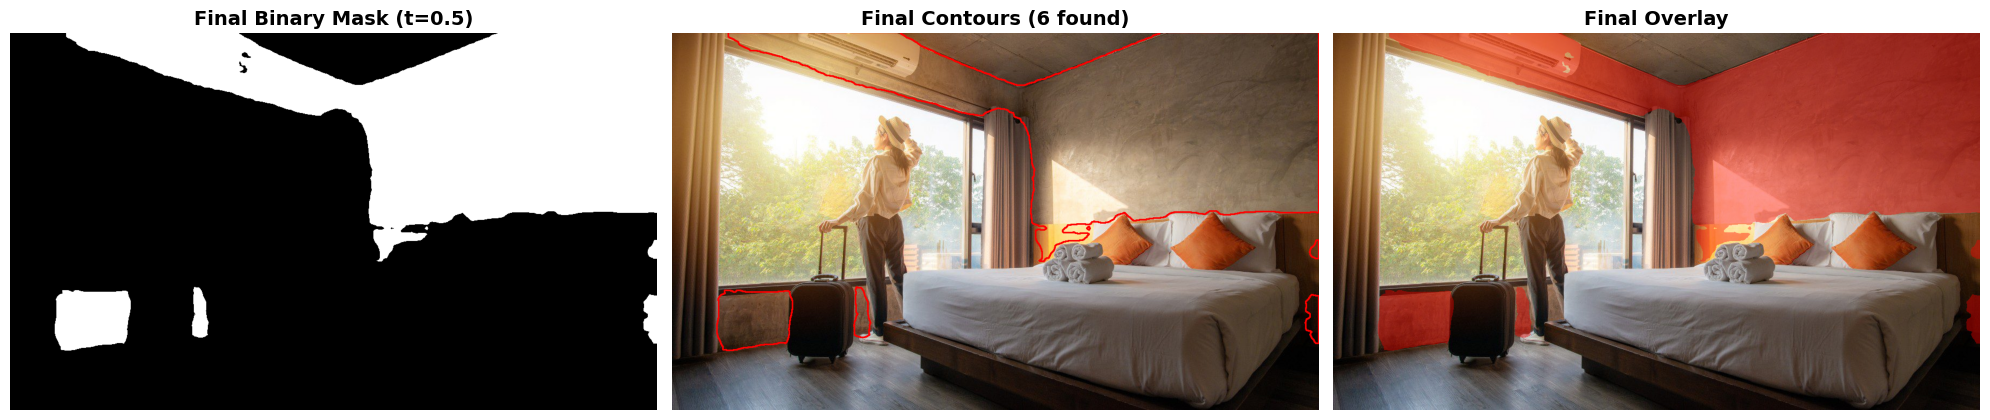


Final Threshold: 0.5
Pixels above threshold: 234,667 (27.94%)
Number of contours: 6


In [11]:
# Set your chosen threshold here
CHOSEN_THRESHOLD = 0.5  # Change this based on your exploration

if 'wall_confidence' in globals() and 'rgb_img' in globals():
    # Create binary mask
    final_mask = wall_confidence > CHOSEN_THRESHOLD
    
    # Extract contours
    binary_uint8 = (final_mask * 255).astype(np.uint8)
    final_contours, _ = cv2.findContours(
        binary_uint8,
        cv2.RETR_EXTERNAL,
        cv2.CHAIN_APPROX_SIMPLE
    )
    
    # Visualization
    fig, axes = plt.subplots(1, 3, figsize=(20, 6))
    
    # Binary mask
    axes[0].imshow(final_mask, cmap='gray')
    axes[0].set_title(f'Final Binary Mask (t={CHOSEN_THRESHOLD})', fontsize=14, fontweight='bold')
    axes[0].axis('off')
    
    # Contours
    contour_img = rgb_img.copy()
    cv2.drawContours(contour_img, final_contours, -1, (255, 0, 0), 2)
    axes[1].imshow(contour_img)
    axes[1].set_title(f'Final Contours ({len(final_contours)} found)', fontsize=14, fontweight='bold')
    axes[1].axis('off')
    
    # Overlay
    overlay = rgb_img.copy().astype(float)
    overlay[final_mask] = overlay[final_mask] * 0.6 + np.array([255, 0, 0]) * 0.4
    axes[2].imshow(overlay.astype(np.uint8))
    axes[2].set_title('Final Overlay', fontsize=14, fontweight='bold')
    axes[2].axis('off')
    
    plt.tight_layout()
    plt.show()
    
    # Print summary
    pixels_selected = np.sum(final_mask)
    percentage = (pixels_selected / final_mask.size) * 100
    print(f"\nFinal Threshold: {CHOSEN_THRESHOLD}")
    print(f"Pixels above threshold: {pixels_selected:,} ({percentage:.2f}%)")
    print(f"Number of contours: {len(final_contours)}")
    
    # Optional: Save results
    # Uncomment to save:
    # output_dir = Path('../results')
    # output_dir.mkdir(exist_ok=True)
    # np.save(output_dir / 'final_mask.npy', final_mask)
    # Image.fromarray((final_mask * 255).astype(np.uint8)).save(output_dir / 'final_mask.png')
    # Image.fromarray(contour_img).save(output_dir / 'final_contours.png')
    # print(f"\nResults saved to {output_dir}")
else:
    print("⚠ Data not loaded. Run the data loading cells first.")